In [20]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('Mall_Customers.csv')

In [3]:
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [4]:
df.shape

(200, 5)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [6]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [7]:
df.isnull().sum()

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [11]:
df.duplicated().sum()

0

In [13]:
X_enc = pd.get_dummies(df,drop_first = True , dtype=int)

In [14]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
X_scaled = sc.fit_transform(X_enc)

In [24]:
from sklearn.cluster import KMeans , DBSCAN

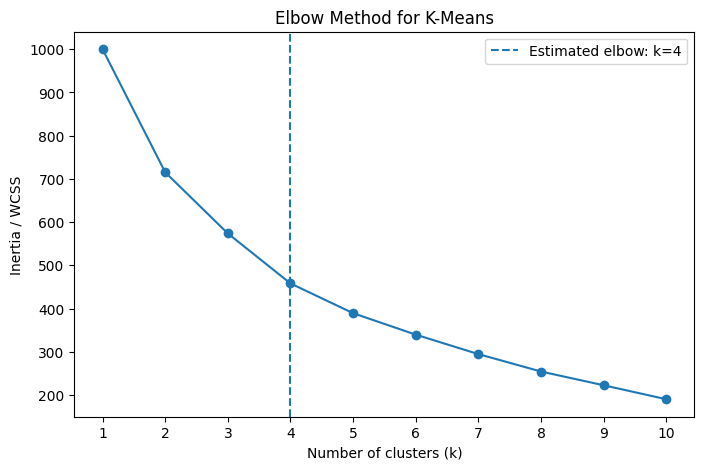

Automatic elbow estimate: k = 4


In [21]:
k_values = list(range(1, 11))
inertias = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertias.append(model.inertia_)

# Simple geometric elbow estimate: maximum distance to line from first to last point.
points = np.column_stack([k_values, inertias]).astype(float)
first, last = points[0], points[-1]
line_vec = last - first
line_unit = line_vec / np.linalg.norm(line_vec)
vec_from_first = points - first
projection = np.outer(vec_from_first @ line_unit, line_unit)
perpendicular = vec_from_first - projection
distances = np.linalg.norm(perpendicular, axis=1)

# Ignore k=1 and the last k as possible elbow candidates.
distances[0] = -np.inf
distances[-1] = -np.inf
elbow_k = int(points[np.argmax(distances), 0])

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertias, marker="o")
plt.axvline(elbow_k, linestyle="--", label=f"Estimated elbow: k={elbow_k}")
plt.xticks(k_values)
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia / WCSS")
plt.title("Elbow Method for K-Means")
plt.legend()
plt.show()

print(f"Automatic elbow estimate: k = {elbow_k}")

In [22]:
kmeans = KMeans(n_clusters=elbow_k, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

print("K-Means cluster counts:")
display(pd.Series(kmeans_labels, name="cluster").value_counts().sort_index().to_frame("count"))

K-Means cluster counts:


,count
cluster,
0,39
1,41
2,57
3,63


In [25]:
dbscan = DBSCAN(eps=0.5, min_samples=5)

labels = dbscan.fit_predict(X_scaled)

In [26]:
display(pd.Series(labels, name="cluster").value_counts().sort_index().to_frame("count"))

,count
cluster,
-1,145
0,5
1,7
2,13
3,5
4,5
5,4
6,16


In [27]:
from sklearn.decomposition import PCA

In [28]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("PCA shape:", X_pca.shape)

PCA shape: (200, 2)


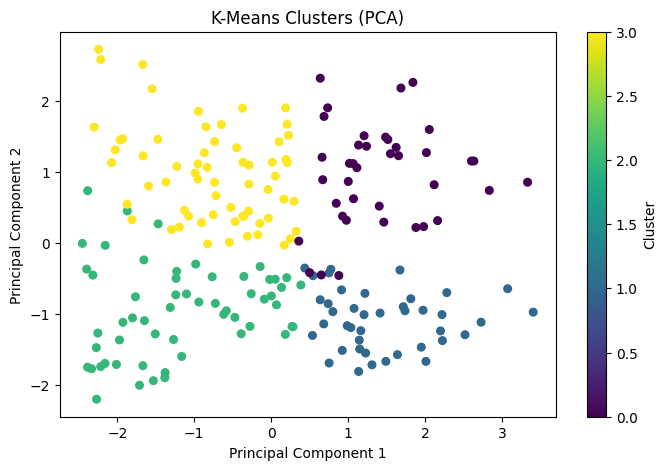

In [29]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=kmeans_labels,
    cmap="viridis",
    s=30
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clusters (PCA)")
plt.colorbar(label="Cluster")
plt.show()

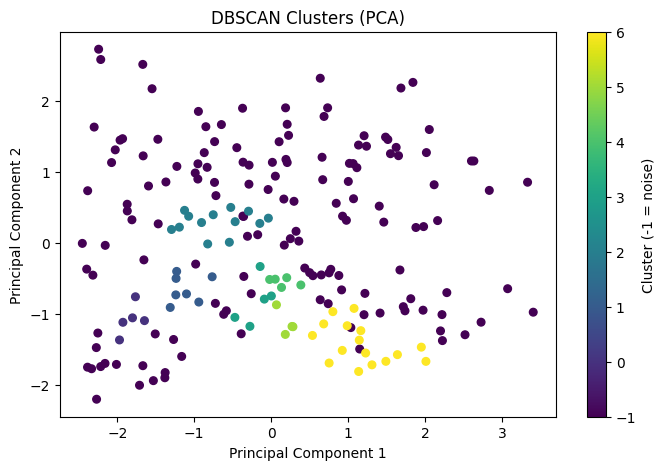

In [30]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=labels,
    cmap="viridis",
    s=30
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("DBSCAN Clusters (PCA)")
plt.colorbar(label="Cluster (-1 = noise)")
plt.show()

In [31]:
print("K-Means:")
print("Number of clusters:", len(set(kmeans_labels)))

print("\nDBSCAN:")
n_dbscan_clusters = len(set(labels) - {-1})
n_noise = (labels == -1).sum()

print("Number of clusters:", n_dbscan_clusters)
print("Number of noise points:", n_noise)
print("Noise percentage:", round(n_noise / len(labels) * 100, 2), "%")

K-Means:
Number of clusters: 4

DBSCAN:
Number of clusters: 7
Number of noise points: 145
Noise percentage: 72.5 %
